In [3]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

print("FraudGuard AI - EDA Started!")

FraudGuard AI - EDA Started!


In [5]:
from pathlib import Path

#find the dataset
data_path = Path("../data/raw/paysim.csv")

if not data_path.exists():
    data_path = Path("data/raw/paysim.csv")

#data only the first 10,000 rows
df = pd.read_csv(data_path, nrows=10000)

#show the first five transactions
display(df.head())

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [7]:
# number of rows and columns 
print("Dataset shep:", df.shape)

#columns names
print("\nColumns:")
print(df.columns.tolist())

#Data types
df.info()

Dataset shep: (10000, 11)

Columns:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            10000 non-null  int64  
 1   type            10000 non-null  str    
 2   amount          10000 non-null  float64
 3   nameOrig        10000 non-null  str    
 4   oldbalanceOrg   10000 non-null  float64
 5   newbalanceOrig  10000 non-null  float64
 6   nameDest        10000 non-null  str    
 7   oldbalanceDest  10000 non-null  float64
 8   newbalanceDest  10000 non-null  float64
 9   isFraud         10000 non-null  int64  
 10  isFlaggedFraud  10000 non-null  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 859.5 KB


In [8]:

from collections import Counter

total_rows = 0
fraud_rows = 0

missing_counts = Counter()
type_counts = Counter()
fraud_by_type = Counter()
transactions_by_step = Counter()
fraud_by_step = Counter()

for chunk in pd.read_csv(data_path, chunksize=100000):
    total_rows += len(chunk)

    fraud_chunk = chunk[chunk["isFraud"] == 1]
    fraud_rows += len(fraud_chunk)

    missing_counts.update(chunk.isna().sum().to_dict())
    type_counts.update(chunk["type"].value_counts().to_dict())
    fraud_by_type.update(fraud_chunk["type"].value_counts().to_dict())
    transactions_by_step.update(chunk["step"].value_counts().to_dict())
    fraud_by_step.update(fraud_chunk["step"].value_counts().to_dict())

print("Total transactions:", total_rows)
print("Fraudulent transactions:", fraud_rows)
print("Legitimate transactions:", total_rows - fraud_rows)
print("Fraud percentage:", round(fraud_rows / total_rows * 100, 4), "%")


Total transactions: 6362620
Fraudulent transactions: 8213
Legitimate transactions: 6354407
Fraud percentage: 0.1291 %


In [9]:

missing_summary = pd.Series(missing_counts).sort_values(
    ascending=False
)

print("Missing values by column:")
display(missing_summary)


Missing values by column:


step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

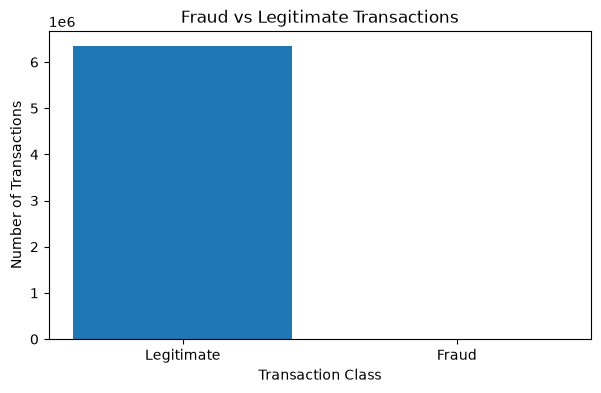

In [10]:

labels = ["Legitimate", "Fraud"]
counts = [total_rows - fraud_rows, fraud_rows]

plt.figure(figsize=(7, 4))
plt.bar(labels, counts)

plt.title("Fraud vs Legitimate Transactions")
plt.ylabel("Number of Transactions")
plt.xlabel("Transaction Class")

plt.show()


In [11]:

type_summary = pd.DataFrame({
    "transactions": pd.Series(type_counts),
    "frauds": pd.Series(fraud_by_type)
}).fillna(0).astype(int)

type_summary["fraud_rate_pct"] = (
    type_summary["frauds"]
    / type_summary["transactions"] * 100
)

display(type_summary.sort_values(
    "transactions", ascending=False
))


,transactions,frauds,fraud_rate_pct
CASH_OUT,2237500,4116,0.183955
PAYMENT,2151495,0,0.000000
CASH_IN,1399284,0,0.000000
TRANSFER,532909,4097,0.768799
DEBIT,41432,0,0.000000


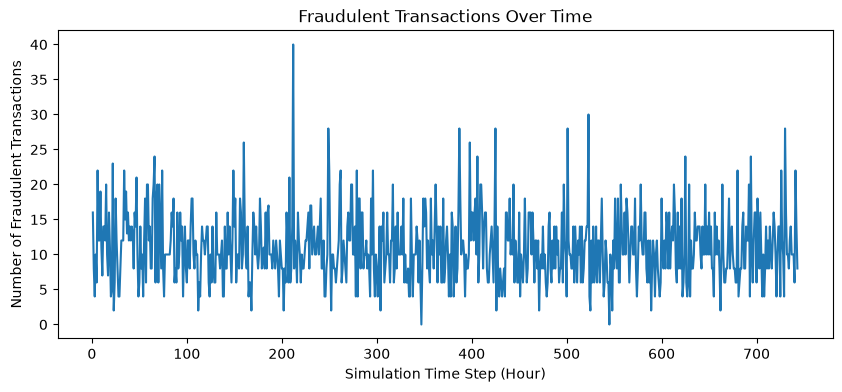

In [12]:

time_summary = pd.DataFrame({
    "transactions": pd.Series(transactions_by_step),
    "frauds": pd.Series(fraud_by_step)
}).fillna(0).sort_index()

plt.figure(figsize=(10, 4))
plt.plot(time_summary.index, time_summary["frauds"])

plt.title("Fraudulent Transactions Over Time")
plt.xlabel("Simulation Time Step (Hour)")
plt.ylabel("Number of Fraudulent Transactions")

plt.show()
